In [1]:
# ─────────────────────────────────────────────
# 환경 준비 — 라이브러리 불러오기 + 한글 폰트 + 시드 고정
# ─────────────────────────────────────────────
# 필요 시 아래 주석을 해제해 설치하세요.
# !pip install numpy pandas scikit-learn matplotlib seaborn -q

import platform
import warnings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# 재현성: 같은 난수를 항상 같게 만듭니다.
np.random.seed(42)

# 한글 폰트 설정 (그래프 안 글자가 깨지지 않도록)
system = platform.system()
if system == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif system == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
else:
    plt.rcParams["font.family"] = "DejaVu Sans"

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")

print("준비 완료! 라이브러리 버전을 확인합니다.")
print("numpy :", np.__version__)
print("pandas:", pd.__version__)

준비 완료! 라이브러리 버전을 확인합니다.
numpy : 2.5.4
pandas: 3.1.0


In [2]:
# ─────────────────────────────────────────────
# 모두마켓 이번 달 주문 데이터 생성 — 자기완결적 스냅샷
# (지난 노드에서 다룬 오염 요소를 적당히 포함시킵니다)
# ─────────────────────────────────────────────
np.random.seed(42)
n = 1500

regions = np.random.choice(["서울", "경기", "부산", "인천", "대구"], n, p=[0.4, 0.25, 0.15, 0.1, 0.1])
membership = np.random.choice(["basic", "silver", "gold", "vip"], n, p=[0.5, 0.25, 0.15, 0.1])
channels = np.random.choice(["web", "app", "app ", "APP"], n, p=[0.5, 0.4, 0.05, 0.05])
categories = np.random.choice(["패션", "뷰티", "식품", "가전", "도서"], n)

prices = np.random.choice([9900, 19900, 29900, 49900, 89900, 129900, 249900], n,
                          p=[0.2, 0.25, 0.2, 0.15, 0.1, 0.06, 0.04])
quantities = np.random.choice([1, 1, 1, 2, 2, 3], n)
amount = (prices * quantities).astype(float)

orders = pd.DataFrame({
    "order_id": [f"O{str(i).zfill(5)}" for i in range(1, n + 1)],
    "customer_age": np.random.normal(35, 9, n).round().astype(int),
    "region": regions,
    "membership": membership,
    "channel": channels,
    "category": categories,
    "price": prices.astype(float),
    "quantity": quantities,
    "amount": amount,
})

# 오염 심기: 결측·이상치·표기 혼재
orders.loc[np.random.choice(n, 60, replace=False), "amount"] = np.nan
orders.loc[np.random.choice(n, 30, replace=False), "customer_age"] = np.nan
orders.loc[5, "customer_age"] = 999             # 입력 실수성 이상치
orders.loc[8, "customer_age"] = -3              # 불가능한 음수
orders.loc[12, "quantity"] = 80                 # 비정상적으로 큰 주문
orders.loc[20, "region"] = " 서울 "             # 앞뒤 공백
orders.loc[21, "region"] = "Seoul"              # 영문 표기
orders.loc[40, "membership"] = "VIP"            # 대소문자 혼재

print("이번 달 주문 데이터 준비 완료:", orders.shape)
orders.head()

이번 달 주문 데이터 준비 완료: (1500, 9)


,order_id,customer_age,region,membership,channel,category,price,quantity,amount
0,O00001,30.0,서울,silver,app,패션,19900.0,1,NaN
1,O00002,24.0,대구,basic,app,가전,249900.0,3,749700.0
2,O00003,45.0,부산,basic,web,패션,19900.0,1,19900.0
3,O00004,24.0,경기,basic,app,뷰티,19900.0,1,NaN
4,O00005,41.0,서울,basic,app,패션,19900.0,1,19900.0


In [3]:
# 예제: 같은 결과를 세 가지 방법으로 — 'amount'에 부가세 10% 더하기
amounts = orders["amount"].dropna().head(8)
print("원본:", amounts.tolist())

# (a) apply: 사용자 정의 함수 적용
def add_vat(x):
    return x * 1.1

by_apply = amounts.apply(add_vat)

# (b) map: 함수도 받지만, dict로 치환할 때 더 자연스러움
by_map = amounts.map(add_vat)

# (c) 벡터화: 함수 없이 연산자 하나
by_vec = amounts * 1.1

print("apply 결과:", by_apply.round(0).tolist())
print("map   결과:", by_map.round(0).tolist())
print("벡터화 결과:", by_vec.round(0).tolist())

원본: [749700.0, 19900.0, 19900.0, 29900.0, 59700.0, 389700.0, 19900.0, 89900.0]
apply 결과: [824670.0, 21890.0, 21890.0, 32890.0, 65670.0, 428670.0, 21890.0, 98890.0]
map   결과: [824670.0, 21890.0, 21890.0, 32890.0, 65670.0, 428670.0, 21890.0, 98890.0]
벡터화 결과: [824670.0, 21890.0, 21890.0, 32890.0, 65670.0, 428670.0, 21890.0, 98890.0]


> **읽는 법:** 셋 다 결과가 같습니다. 그래서 **결과만 보고는** 어느 도구를 썼는지 알 수 없죠. 차이는 다음 두 셀(가독성과 속도)에서 드러납니다.

In [4]:
# 예제: 'map'이 가장 어울리는 자리 — dict 치환
gender_kr_to_num = {"M": 1, "F": 0}
sample_gender = pd.Series(["M", "F", "F", "M", "F"])

# map은 dict를 그대로 받습니다. 이게 가장 자연스러움.
print("map(dict):", sample_gender.map(gender_kr_to_num).tolist())

# 같은 일을 apply로 하려면 dict.get을 래핑해야 합니다(가독성 떨어짐).
print("apply(lambda):", sample_gender.apply(lambda x: gender_kr_to_num.get(x)).tolist())

map(dict): [1, 0, 0, 1, 0]
apply(lambda): [1, 0, 0, 1, 0]


> **읽는 법:** "이 값을 저 값으로 바꿔라"가 명확한 dict 치환은 **`map`이 가장 읽기 좋습니다**. 같은 일을 `apply`로 하면 `lambda x: dict.get(x)` 같은 군더더기가 붙습니다. 의도를 가장 잘 드러내는 도구를 고르는 것이 곧 가독성입니다.

In [5]:
# 예제: 속도 비교 — 10만 건에 '부가세 10% 더하기'
big = pd.Series(np.random.randint(1000, 100_000, 100_000).astype(float))

# (a) apply
start = time.time()
_ = big.apply(lambda x: x * 1.1)
t_apply = time.time() - start

# (b) map
start = time.time()
_ = big.map(lambda x: x * 1.1)
t_map = time.time() - start

# (c) 벡터화
start = time.time()
_ = big * 1.1
t_vec = time.time() - start

print(f"apply  : {t_apply*1000:.1f} ms")
print(f"map    : {t_map*1000:.1f} ms")
print(f"벡터화 : {t_vec*1000:.1f} ms")
print(f"→ 벡터화가 apply보다 약 {t_apply/max(t_vec, 1e-9):.0f}배 빠릅니다 (환경에 따라 다름)")

apply  : 7.4 ms
map    : 7.2 ms
벡터화 : 0.1 ms
→ 벡터화가 apply보다 약 65배 빠릅니다 (환경에 따라 다름)


> **읽는 법:** `apply`/`map`은 값을 하나씩 함수에 넣어 돌려받는 구조라 파이썬 반복문에 가깝습니다. 벡터화는 NumPy의 C 코드로 한 번에 처리되므로 자릿수가 다른 속도가 나옵니다. 데이터가 작을 때는 차이가 크지 않지만, **수십만~수백만 건**이 되면 이 차이가 분석 가능 시간 자체를 결정합니다.

## 데이터로 확인해 봅시다

- `df["channel"].str.lower().str.strip()`처럼 **pandas 내장 메서드**가 있는 경우엔 거의 항상 그것이 답입니다. 이미 벡터화돼 있어 빠릅니다.
- "VIP 등급은 1.5, GOLD는 1.2, …" 같은 **사전 치환**은 `map`이 가장 가독성 좋습니다.
- 여러 컬럼을 함께 보고 조건부로 새 값을 만들 때는 `df.apply(func, axis=1)`가 어울립니다. 단, 느립니다 — 가능하면 `np.where`·`np.select`로 벡터화하세요.

> 📌 **다른 산업에서는?** 마케팅에서는 `customer_segment` 코드(`A`, `B`, `C`)를 가중치로 바꿀 때 `map`이, 금융에서는 신용점수 구간 라벨링에 `np.where`/`np.select` 벡터화가, 헬스케어에서는 진단 코드를 카테고리 분류로 매핑할 때 `map`이 가장 자연스럽습니다.

In [6]:
# 예제: 모두마켓 데이터에 세 방법(apply · map · np.where)을 모두 적용 — '주문 등급' 만들기
# 규칙: amount >= 100000 → 'high', 30000 이상 → 'mid', 그 외 'low'

# (a) apply (행 단위 — 가독성은 좋지만 느림)
def classify(amount):
    if pd.isna(amount):
        return np.nan
    if amount >= 100_000:
        return "high"
    elif amount >= 30_000:
        return "mid"
    return "low"

orders["grade_apply"] = orders["amount"].apply(classify)

# (b) 벡터화 (np.select가 'if-elif-else'의 벡터화 버전)
orders["grade_vec"] = np.select(
    [orders["amount"] >= 100_000, orders["amount"] >= 30_000],
    ["high", "mid"],
    default="low"
)
# 결측은 결측으로 두기
orders.loc[orders["amount"].isna(), "grade_vec"] = np.nan

# 결과가 같은지 확인 (결측 처리도 함께)
print("두 방식 결과 동일?:", (orders["grade_apply"].fillna("X") == orders["grade_vec"].fillna("X")).all())
print(orders[["amount", "grade_apply", "grade_vec"]].head())

두 방식 결과 동일?: True
     amount grade_apply grade_vec
0       NaN         NaN       NaN
1  749700.0        high      high
2   19900.0         low       low
3       NaN         NaN       NaN
4   19900.0         low       low


> **읽는 법:** `np.select`는 "조건 리스트, 그에 대응하는 값 리스트, 그리고 기본값"을 받아 if-elif-else 분기를 **벡터화**합니다. 결과는 `apply`와 같지만 속도는 훨씬 빠릅니다. **읽기에 무리 없을 정도까지는** 벡터화로 작성하는 것이 좋은 습관입니다.

### 스스로 해보자! ✏️ (1)

> 정답은 하나가 아닙니다. 일단 실행해보세요.

1. **(따라하기)** `orders["membership"]`을 `{basic: 1, silver: 2, gold: 3, vip: 4}` 가중치로 바꾼 새 컬럼 `membership_score`를 만드세요. 가장 읽기 좋은 도구를 고르세요.
2. **(응용)** `orders["customer_age"]`에 1을 더해 `age_next_year` 컬럼을 만드세요. 같은 일을 (a) `apply`, (b) 벡터화 두 방식으로 작성해 결과가 같은지 확인하세요.
3. **(생각해보기)** "이 작업은 셋 중 무엇이 가장 자연스러운가?"를 결정하는 기준은 무엇일까요? (힌트: 치환인지, 한 값에 함수를 거는 것인지, 컬럼 전체 연산인지)

In [7]:
# 스스로 해보자! (1)
# 아래 주석(#)을 지우고 빈칸(___)을 채운 뒤 실행해보세요.

# weight = {"basic": 1, "silver": 2, "gold": 3, "vip": 4}
# orders["membership_score"] = orders["membership"].___(weight)   # 1) map / apply 중 자연스러운 것은?
# print(orders[["membership", "membership_score"]].head())

# orders["age_next_year_apply"] = orders["customer_age"].apply(lambda x: ___)
# orders["age_next_year_vec"]   = orders["customer_age"] ___ 1
# print((orders["age_next_year_apply"] == orders["age_next_year_vec"]).all())

<details>
<summary>💡 힌트 (클릭)</summary>

```python
weight = {"basic": 1, "silver": 2, "gold": 3, "vip": 4}
orders["membership_score"] = orders["membership"].map(weight)   # dict 치환은 map이 자연스러움
print(orders[["membership", "membership_score"]].head())

orders["age_next_year_apply"] = orders["customer_age"].apply(lambda x: x + 1)
orders["age_next_year_vec"]   = orders["customer_age"] + 1
print((orders["age_next_year_apply"] == orders["age_next_year_vec"]).all())
```

여기서 `"VIP"`(대문자)는 `weight` 딕셔너리에 없으므로 결과에 `NaN`이 생깁니다. 표기 혼재를 정제하지 않으면 인코딩에서 그대로 누락된다는 신호입니다. (Part 2의 인코딩 이전에 정제가 왜 필요한지 보여주는 장면입니다.)

</details>

### ✅ 짚고 넘어가기

다음 질문에 답할 수 있으면 다음 Part로 넘어가세요. 틀려도 괜찮습니다.

1. `apply`, `map`, 벡터화 중 일반적으로 가장 빠른 것은 무엇인가요?
2. dict로 "이 값을 저 값으로" 치환할 때 가장 자연스러운 도구는 무엇인가요?
3. `if-elif-else` 분기를 벡터화하려면 어떤 함수를 떠올릴 수 있나요?

> 💡 **다음 Part 예고:** 지금까지는 **값을 변환**하는 법을 봤습니다. 이제 **글자 카테고리**(예: `region`, `membership`)를 모델이 읽을 **숫자**로 바꿀 차례입니다. "어떤 숫자로 바꿔야 하는가"가 카테고리의 성격에 따라 달라집니다.

In [8]:
# 인코딩 전 정제: 공백·표기·대소문자 혼재 통일
orders["region_clean"]     = orders["region"].str.strip().replace({"Seoul": "서울"})
orders["membership_clean"] = orders["membership"].str.lower()
orders["channel_clean"]    = orders["channel"].str.strip().str.lower()

print("region:",     sorted(orders["region_clean"].unique()))
print("membership:", sorted(orders["membership_clean"].unique()))
print("channel:",    sorted(orders["channel_clean"].unique()))

region: ['경기', '대구', '부산', '서울', '인천']
membership: ['basic', 'gold', 'silver', 'vip']
channel: ['app', 'web']


In [9]:
# (a) Label Encoding — 카테고리에 정수 한 개씩 (임의 순서)
# 가장 간단한 방법: pd.factorize  (또는 sklearn.preprocessing.LabelEncoder)
region_codes, region_labels = pd.factorize(orders["region_clean"])
print("매핑(임의 순서):", dict(enumerate(region_labels)))
print("앞 10개:", region_codes[:10])

매핑(임의 순서): {0: '서울', 1: '대구', 2: '부산', 3: '경기', 4: '인천'}
앞 10개: [0 1 2 3 0 0 0 4 3 2]


In [10]:
# (b) Ordinal Encoding — '진짜 순서'가 있는 카테고리에
# membership: basic < silver < gold < vip
member_order = {"basic": 1, "silver": 2, "gold": 3, "vip": 4}
orders["membership_ord"] = orders["membership_clean"].map(member_order)

print(orders[["membership_clean", "membership_ord"]].head())
print("\n결측 발생 여부:", orders["membership_ord"].isna().sum(), "건")

  membership_clean  membership_ord
0           silver               2
1            basic               1
2            basic               1
3            basic               1
4            basic               1

결측 발생 여부: 0 건


In [11]:
# (c) One-Hot Encoding — 순서 없는 카테고리에 가장 안전
# pandas의 pd.get_dummies가 가장 간편합니다.
one_hot = pd.get_dummies(orders["region_clean"], prefix="region", dtype=int)
print("One-Hot 결과(앞 5행):")
display(one_hot.head())
print("컬럼 수:", one_hot.shape[1], "— region 고윳값 수와 같습니다")

One-Hot 결과(앞 5행):


,region_경기,region_대구,region_부산,region_서울,region_인천
0,0,0,0,1,0
1,0,1,0,0,0
2,0,0,1,0,0
3,1,0,0,0,0
4,0,0,0,1,0


컬럼 수: 5 — region 고윳값 수와 같습니다


In [12]:
# 예제: 카디널리티가 크면? — '상품 ID'를 One-Hot 하는 경우
fake_product = pd.Series([f"P{str(i).zfill(4)}" for i in np.random.randint(1, 500, 1500)])
print("고윳값 수:", fake_product.nunique())
print("One-Hot 시 만들어질 컬럼 수:", fake_product.nunique())
# 실제로는 만들지 않습니다 — 메모리가 폭발합니다.

고윳값 수: 469
One-Hot 시 만들어질 컬럼 수: 469


In [13]:
# 스스로 해보자! (2)
# 1) channel_clean One-Hot
# ch_oh = pd.get_dummies(orders["channel_clean"], prefix="ch", dtype=int)
# orders = pd.concat([orders, ch_oh], axis=1)
# print(orders.filter(like="ch_").head())

# 2) drop_first 옵션
# cat_oh = pd.get_dummies(orders["category"], prefix="cat", dtype=int, drop_first=___)
# print(cat_oh.shape)   # 컬럼이 한 개 줄어든 것을 확인

In [14]:
# 예제: 세 가지 스케일러를 직접 비교 — 'amount'에 적용
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

amt = orders[["amount"]].dropna()   # 2D로 두는 게 sklearn 관례

mm = MinMaxScaler().fit_transform(amt)
ss = StandardScaler().fit_transform(amt)
rs = RobustScaler().fit_transform(amt)

scaled = pd.DataFrame({
    "original": amt["amount"].values,
    "minmax":   mm.flatten(),
    "standard": ss.flatten(),
    "robust":   rs.flatten(),
})
print(scaled.describe().round(2))

ModuleNotFoundError: No module named 'sklearn'

> **읽는 법:** `minmax`는 0과 1 사이에, `standard`는 평균 0·표준편차 1 근방에 놓입니다. `robust`는 명확한 고정 범위가 없지만, 중앙값을 0으로 맞추고 IQR로 나눕니다. 통계량을 비교하면 셋의 성격 차이가 한눈에 보입니다.

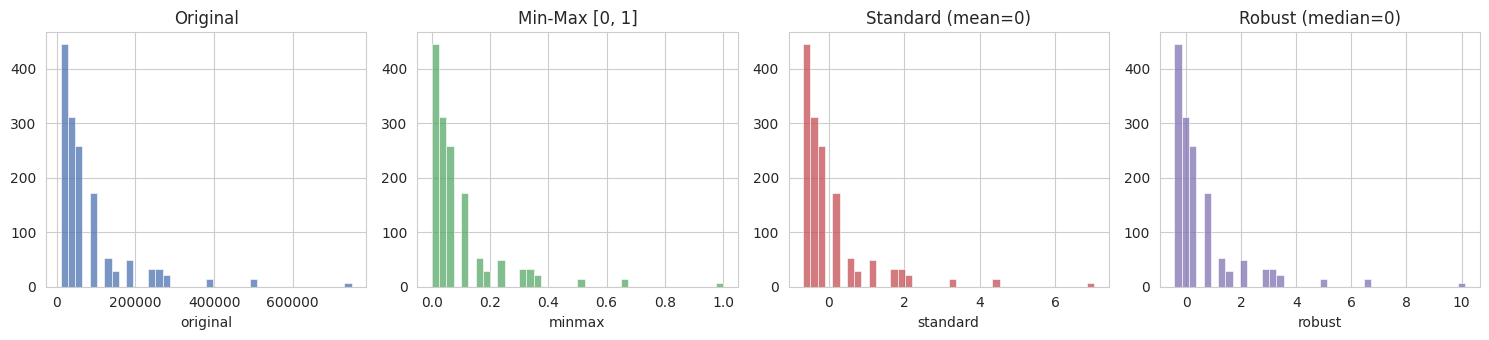

In [ ]:
# 예제: 그림으로 비교 — 이상치가 있을 때 각 스케일러가 어떻게 반응하나
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
sns.histplot(scaled["original"], bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title("Original")

sns.histplot(scaled["minmax"], bins=40, ax=axes[1], color="#55A868")
axes[1].set_title("Min-Max [0, 1]")

sns.histplot(scaled["standard"], bins=40, ax=axes[2], color="#C44E52")
axes[2].set_title("Standard (mean=0)")

sns.histplot(scaled["robust"], bins=40, ax=axes[3], color="#8172B2")
axes[3].set_title("Robust (median=0)")

for ax in axes:
    ax.set_ylabel("")
plt.tight_layout(); plt.show()

> **읽는 법:** 네 그래프의 **모양이 똑같습니다.** 세 스케일러 모두 "빼고 나누는" 선형 변환이라 분포의 모양(오른쪽 꼬리)은 그대로 두고 **x축 눈금만 바꾸기** 때문입니다. 차이는 x축에서 읽어야 합니다. Min-Max는 최댓값(이상치)이 1이 되도록 맞추다 보니 대부분의 주문이 0~0.1 근처에 몰립니다. Standard는 이상치에 끌려간 평균·표준편차가 기준이라 이상치가 약 7까지 나갑니다. Robust는 중앙값을 0, IQR을 1로 잡기 때문에 대부분의 주문이 −0.5~1 구간에 고르게 펼쳐집니다. 즉 **스케일링은 이상치를 없애거나 분포를 바꾸지 않습니다.** 분포 모양 자체를 바꾸려면 log 변환 같은 비선형 변환이 필요합니다.

In [ ]:
# 예제: 이상치를 추가하면 대부분의 데이터의 스케일이 어떻게 변하나?
amt_out = pd.concat([amt, pd.DataFrame({"amount": [5_000_000] * 5})], ignore_index=True)
n = len(amt)

for name, Scaler in [("Min-Max", MinMaxScaler), ("Standard", StandardScaler), ("Robust", RobustScaler)]:
    before = Scaler().fit_transform(amt).ravel()
    after  = Scaler().fit_transform(amt_out).ravel()[:n]   # 원래 데이터 부분만 비교
    q1b, q3b = np.percentile(before, [25, 75])
    q1a, q3a = np.percentile(after,  [25, 75])
    print(f"{name:8s}  Q1~Q3  추가 전: {q1b:6.2f} ~ {q3b:5.2f}   추가 후: {q1a:6.2f} ~ {q3a:5.2f}")

Min-Max   Q1~Q3  추가 전:   0.01 ~  0.11   추가 후:   0.00 ~  0.02
Standard  Q1~Q3  추가 전:  -0.58 ~  0.15   추가 후:  -0.24 ~ -0.01
Robust    Q1~Q3  추가 전:  -0.28 ~  0.72   추가 후:  -0.28 ~  0.72


> **읽는 법:** 이상치 5건만 추가했는데 Min-Max와 Standard는 나머지 데이터의 위치와 폭이 크게 바뀝니다. Robust는 **전혀 변하지 않습니다.** 중앙값과 IQR은 극단값 몇 개에 흔들리지 않기 때문입니다. 이것이 "Robust가 이상치에 강하다"는 말의 정확한 의미입니다.

In [ ]:
# 예제: fit / transform 분리 — 실서비스의 정석
# 학습 데이터로 'fit'한 통계량을 새 데이터에도 똑같이 'transform'에 써야 합니다.
train = orders.iloc[:1000][["amount"]].dropna()
test  = orders.iloc[1000:][["amount"]].dropna()

scaler = StandardScaler()
scaler.fit(train)                              # train의 평균·표준편차를 기억
train_scaled = scaler.transform(train)         # 같은 기준으로 변환
test_scaled  = scaler.transform(test)          # test에도 같은 기준 적용

print("train 평균:", round(train_scaled.mean(), 3), "표준편차:", round(train_scaled.std(), 3))
print("test  평균:", round(test_scaled.mean(), 3),  "표준편차:", round(test_scaled.std(), 3))

train 평균: -0.0 표준편차: 1.0
test  평균: -0.022 표준편차: 0.922


> **읽는 법:** **`fit`은 학습 데이터에서만** 합니다. test 데이터까지 합쳐 `fit`하면 모델이 미래(평가 시점) 정보를 미리 보는 **데이터 누수(data leakage)** 가 됩니다. 학습 데이터로 `fit`한 통계량을 test에 그대로 `transform`하는 것이 약속입니다.

> 💡 **더 알고 싶다면 (선택):** 분포가 매우 치우친 변수(`log`-normal 같은)는 **로그 변환**(`np.log1p`)을 먼저 한 뒤 스케일링하면 더 안정적입니다. 가격·소득·인구 같은 변수에서 자주 씁니다.

## 데이터로 확인해 봅시다

- **스케일링이 필요한 모델:** k-NN, k-Means, SVM, 선형 회귀(정규화 포함), 로지스틱 회귀, 신경망.
- **스케일링이 필요 없는 모델:** Decision Tree, Random Forest, XGBoost, LightGBM. (순서만 보기 때문)
- 분석가는 모델을 정하기 전부터 **분포의 단위가 다르면 일단 스케일링을 의식**해 두는 게 좋습니다.

> 📌 **다른 산업에서는?** 마케팅은 광고비(만 원~억 원)와 클릭률(0~1) 같이 자릿수가 극단적으로 다른 변수를 함께 다룰 때 스케일링이 필수입니다. 금융은 신용 점수·소득·부채 같이 단위가 다른 변수를 거리 기반 사기탐지에 쓸 때, 헬스케어는 키·몸무게·혈압·검사 수치를 함께 입력하는 임상 모델에서 표준화가 기본입니다.

### 스스로 해보자! ✏️ (3)

> 정답은 하나가 아닙니다. 일단 실행해보세요.

1. **(따라하기)** `quantity` 컬럼에 Min-Max 스케일러를 적용한 결과를 새 컬럼 `quantity_mm`으로 만드세요.
2. **(응용)** `quantity`에는 이상치(80)가 있습니다. Min-Max 결과의 분포를 히스토그램으로 그려보고, 이상치 때문에 본체가 한쪽에 뭉치는지 확인하세요.
3. **(생각해보기)** 같은 `quantity`에 Robust 스케일러를 적용하면 어떻게 달라질까요? 직접 비교해보세요.

In [ ]:
# 스스로 해보자! (3)
# from sklearn.preprocessing import MinMaxScaler, RobustScaler

# qty = orders[["quantity"]]
# orders["quantity_mm"]     = MinMaxScaler().fit_transform(qty)
# orders["quantity_robust"] = RobustScaler().fit_transform(qty)

# fig, axes = plt.subplots(1, 2, figsize=(12, 3))
# sns.histplot(orders["quantity_mm"],     bins=30, ax=axes[0]); axes[0].set_title("Min-Max")
# sns.histplot(orders["quantity_robust"], bins=30, ax=axes[1]); axes[1].set_title("Robust")
# plt.tight_layout(); plt.show()

In [ ]:
# 예제: '단계 변수'로 쓴 정제와 'chaining'으로 쓴 정제 — 결과는 같음

# (a) 단계 변수 방식 (전통)
step1 = orders.dropna(subset=["amount", "customer_age"])
step2 = step1[(step1["customer_age"] > 0) & (step1["customer_age"] < 120)]
step3 = step2.assign(
    region_clean=step2["region"].str.strip().replace({"Seoul": "서울"}),
    amount_log=np.log1p(step2["amount"]),
)
clean_a = step3.sort_values("amount", ascending=False).reset_index(drop=True)

# (b) method chaining 방식 (체이닝)
clean_b = (
    orders
    .dropna(subset=["amount", "customer_age"])
    .query("0 < customer_age < 120")
    .assign(
        region_clean=lambda d: d["region"].str.strip().replace({"Seoul": "서울"}),
        amount_log=lambda d: np.log1p(d["amount"]),
    )
    .sort_values("amount", ascending=False)
    .reset_index(drop=True)
)

# 두 결과가 같은가?
print("두 방식 결과 동일?:", clean_a.equals(clean_b))
print("정제 후 행 수:", clean_b.shape[0])
clean_b.head(3)

두 방식 결과 동일?: True
정제 후 행 수: 1411
  order_id  customer_age region membership channel category     price  quantity    amount grade_apply grade_vec region_clean membership_clean channel_clean  membership_ord  amount_log
0   O00659          33.0   경기      basic     app     도서  249900.0         3  749700.0        high      high         경기            basic           app               1    13.52743
1   O00096          39.0   경기     silver     app     뷰티  249900.0         3  749700.0        high      high         경기           silver           app               2    13.52743
2   O00531          49.0   인천      basic     web     가전  249900.0         3  749700.0        high      high         인천            basic           web               1    13.52743


In [ ]:
# 예제: query로 같은 필터 작성
# 1) 전통 방식
cond = (orders["customer_age"] > 0) & (orders["customer_age"] < 120) & (orders["amount"] >= 30000)
trad = orders[cond]

# 2) query 방식
q = orders.query("0 < customer_age < 120 and amount >= 30000")

print("동일?", trad.equals(q))
print("건수:", len(q))

동일? True
건수: 776


In [ ]:
# 스스로 해보자! (4)
# 아래 빈칸(___)을 채우고 실행해보세요.

result = (
    orders
    .dropna(subset=["amount"])
    .query("0 < customer_age < 120")
    .assign(
        channel_clean=lambda d: d["channel"].str.strip().str.lower(),
        amount_log=lambda d: np.log1p(d["amount"]),
    )
    .sort_values("amount", ascending=False)
    .reset_index(drop=True)
)
print(result.shape)
result.head(3)

(1411, 16)
  order_id  customer_age region membership channel category     price  quantity    amount grade_apply grade_vec region_clean membership_clean channel_clean  membership_ord  amount_log
0   O00659          33.0   경기      basic     app     도서  249900.0         3  749700.0        high      high         경기            basic           app               1    13.52743
1   O00096          39.0   경기     silver     app     뷰티  249900.0         3  749700.0        high      high         경기           silver           app               2    13.52743
2   O00531          49.0   인천      basic     web     가전  249900.0         3  749700.0        high      high         인천            basic           web               1    13.52743


<details>
<summary>💡 힌트 (클릭)</summary>

```python
result = (
    orders
    .dropna(subset=["amount"])
    .query("0 < customer_age < 120")
    .assign(
        channel_clean=lambda d: d["channel"].str.strip().str.lower(),
        amount_log=lambda d: np.log1p(d["amount"]),
    )
    .sort_values("amount", ascending=False)
    .reset_index(drop=True)
)
print(result.shape)
result.head(3)
```

`assign(... = lambda d: ...)`에서 `d`는 직전 단계까지 처리된 DataFrame입니다. 그래서 새 컬럼이 *체이닝 중간 상태*를 기준으로 만들어집니다. 이 한 줄 트릭이 chaining의 강점이에요.

</details>

### ✅ 짚고 넘어가기

1. method chaining의 가장 큰 장점을 한 문장으로 말할 수 있나요?
2. 체이닝 중에 새 컬럼을 만들 때 `assign(... = lambda d: ...)`처럼 람다를 쓰는 이유는 무엇인가요?
3. `df[df["age"] > 0]`와 `df.query("age > 0")` 중 어떤 것이 더 길어졌을 때 읽기 좋을까요?

> 💡 **다음 Part 예고:** Chaining이 흐름을 보기 좋게 만들었지만, **다른 데이터셋에 똑같이 적용**하려면 또 복사·붙여넣기를 해야 합니다. 다음 Part는 단계 자체를 **함수**로 만들어, 체이닝 안에서 함수 단위로 조립할 수 있게 해주는 **`.pipe()`** 입니다.

In [ ]:
# 예제: 단계마다 함수로 빼기 — '한 함수 = 한 책임'
def clean_strings(df):
    # 공백·대소문자·표기 혼재를 정리합니다.
    return df.assign(
        region=df["region"].str.strip().replace({"Seoul": "서울"}),
        membership=df["membership"].str.lower(),
        channel=df["channel"].str.strip().str.lower(),
    )

def drop_invalid(df, age_min=0, age_max=120, qty_max=20):
    # 불가능한 값(나이 범위·과대 수량)과 결측을 제거합니다.
    return (
        df
        .dropna(subset=["amount", "customer_age"])
        .query("@age_min < customer_age < @age_max")
        .query("quantity <= @qty_max")
    )

def add_features(df):
    # 분석에 쓸 파생 컬럼을 추가합니다.
    return df.assign(
        amount_log=lambda d: np.log1p(d["amount"]),
        is_premium=lambda d: d["membership"].isin(["gold", "vip"]).astype(int),
    )

print("세 함수가 준비됐습니다. 다음 셀에서 한 줄로 조립합니다.")

세 함수가 준비됐습니다. 다음 셀에서 한 줄로 조립합니다.


In [ ]:
# 예제: 한 줄로 조립
cleaned = (
    orders
    .pipe(clean_strings)
    .pipe(drop_invalid, age_min=10, age_max=80, qty_max=10)
    .pipe(add_features)
)

print("원본:", orders.shape, "→ 정제 후:", cleaned.shape)
cleaned.head(3)

원본: (1500, 15) → 정제 후: (1404, 17)
  order_id  customer_age region membership channel category     price  quantity    amount grade_apply grade_vec region_clean membership_clean channel_clean  membership_ord  amount_log  is_premium
1   O00002          24.0   대구      basic     app     가전  249900.0         3  749700.0        high      high         대구            basic           app               1   13.527430           0
2   O00003          45.0   부산      basic     web     패션   19900.0         1   19900.0         low       low         부산            basic           web               1    9.898525           0
4   O00005          41.0   서울      basic     app     패션   19900.0         1   19900.0         low       low         서울            basic           app               1    9.898525           0


In [ ]:
# 예제: 인코딩/스케일링 함수 추가
from sklearn.preprocessing import RobustScaler

def encode_categories(df):
    # membership은 Ordinal, region·channel·category는 One-Hot.
    order_map = {"basic": 1, "silver": 2, "gold": 3, "vip": 4}
    out = df.assign(membership_ord=df["membership"].map(order_map))
    # One-Hot
    out = pd.concat(
        [out,
         pd.get_dummies(out["region"], prefix="region", dtype=int),
         pd.get_dummies(out["channel"], prefix="ch", dtype=int),
         pd.get_dummies(out["category"], prefix="cat", dtype=int)],
        axis=1
    )
    return out

def scale_numeric(df, cols=("customer_age", "amount", "quantity")):
    # 수치형 컬럼을 RobustScaler로 스케일링.
    scaler = RobustScaler()
    scaled = scaler.fit_transform(df[list(cols)])
    scaled_df = pd.DataFrame(scaled, columns=[f"{c}_scaled" for c in cols], index=df.index)
    return pd.concat([df, scaled_df], axis=1)

# 전체 파이프라인 한 줄
pipeline_result = (
    orders
    .pipe(clean_strings)
    .pipe(drop_invalid, age_min=10, age_max=80, qty_max=10)
    .pipe(add_features)
    .pipe(encode_categories)
    .pipe(scale_numeric)
)

print("최종 shape:", pipeline_result.shape)
print("새로 생긴 컬럼 일부:", [c for c in pipeline_result.columns if "scaled" in c or c.startswith("region_")][:8])

최종 shape: (1404, 32)
새로 생긴 컬럼 일부: ['region_clean', 'region_경기', 'region_대구', 'region_부산', 'region_서울', 'region_인천', 'customer_age_scaled', 'amount_scaled']


In [ ]:
# 스스로 해보자! (5)
def add_amount_class(df):
    return df.assign(
        amount_class=np.where(df["amount"] >= 100_000, "high", "low")
    )

orders_v2 = (
    orders
    .pipe(clean_strings)
    .pipe(drop_invalid)
    .pipe(add_features)
    .pipe(add_amount_class)   # 새 함수 끼우기
)
print(orders_v2[["amount", "amount_class"]].head())
print(orders_v2["amount_class"].value_counts())

     amount amount_class
1  749700.0         high
2   19900.0          low
4   19900.0          low
6   59700.0          low
7  389700.0         high
amount_class
low     1162
high     248
Name: count, dtype: int64


# 🧪 종합 실습 — CSV → 정제 → 저장 end-to-end 파이프라인

오늘의 도구를 모두 모아 **한 함수**로 묶어봅니다. 이 함수는 다음 달의 여러분(혹은 다른 팀원)이 새 데이터를 받았을 때 **한 줄로 부를** 수 있어야 합니다.

작업 흐름:

```text
[1] 원본 CSV 로드   →  [2] 정제   →  [3] 인코딩/스케일링   →  [4] 저장
```

각 단계를 함수로 만들고, `.pipe()`로 조립합니다. 마지막에 결과를 CSV로 저장하고 다시 읽어 검증합니다.

> 💡 **데이터셋:** 모두마켓 이번 달 주문이 CSV 파일로 들어왔다고 가정합니다. 아래 셀이 그 CSV를 임시 폴더에 만들어줍니다(자기완결적 스냅샷).

In [ ]:
# ─────────────────────────────────────────────
# 시나리오 0 — 원본 CSV 파일 준비 (실무에서는 외부에서 받아오는 단계)
# ─────────────────────────────────────────────
work_dir = Path("d006_work")
work_dir.mkdir(exist_ok=True)
input_csv  = work_dir / "orders_raw.csv"
output_csv = work_dir / "orders_clean.csv"

orders.to_csv(input_csv, index=False)
print("원본 CSV 저장:", input_csv, "—", input_csv.stat().st_size, "bytes")

원본 CSV 저장: d006_work/orders_raw.csv — 120973 bytes


## 시나리오 1 — 단계 함수 정의 (한 함수 = 한 책임)

각 단계를 작은 함수로 빼서, 함수 이름만 봐도 무엇을 하는지 보이게 만듭니다.

In [ ]:
# 시나리오 1 — 단계 함수들
def load_orders(path):
    # CSV에서 주문 데이터를 읽어 옵니다.
    return pd.read_csv(path)

def clean_strings_full(df):
    # 문자열 컬럼의 공백·대소문자·표기 혼재를 정리합니다.
    return df.assign(
        region=df["region"].str.strip().replace({"Seoul": "서울"}),
        membership=df["membership"].str.lower(),
        channel=df["channel"].str.strip().str.lower(),
    )

def drop_invalid_rows(df, age_min=10, age_max=80, qty_max=10):
    # 불가능한 값과 결측을 제거합니다.
    return (
        df
        .dropna(subset=["amount", "customer_age"])
        .query("@age_min < customer_age < @age_max")
        .query("quantity <= @qty_max")
        .drop_duplicates()
        .reset_index(drop=True)
    )

def add_derived(df):
    # 분석용 파생 컬럼을 추가합니다.
    return df.assign(
        amount_log=lambda d: np.log1p(d["amount"]),
        is_premium=lambda d: d["membership"].isin(["gold", "vip"]).astype(int),
        amount_class=lambda d: np.where(d["amount"] >= 100_000, "high",
                                np.where(d["amount"] >= 30_000, "mid", "low"))
    )

def encode_full(df):
    # membership=Ordinal, 나머지=One-Hot.
    order_map = {"basic": 1, "silver": 2, "gold": 3, "vip": 4}
    out = df.assign(membership_ord=df["membership"].map(order_map))
    one_hots = [
        pd.get_dummies(out["region"],   prefix="region", dtype=int),
        pd.get_dummies(out["channel"],  prefix="ch",     dtype=int),
        pd.get_dummies(out["category"], prefix="cat",    dtype=int),
    ]
    return pd.concat([out] + one_hots, axis=1)

def scale_with_robust(df, cols=("customer_age", "amount", "quantity")):
    # 수치형 컬럼을 Robust로 스케일링하고 _scaled 접미사를 추가합니다.
    scaler = RobustScaler()
    scaled = scaler.fit_transform(df[list(cols)])
    scaled_df = pd.DataFrame(scaled,
                             columns=[f"{c}_scaled" for c in cols],
                             index=df.index)
    return pd.concat([df, scaled_df], axis=1)

print("단계 함수 6개 정의 완료. 다음 셀에서 한 줄로 조립합니다.")

단계 함수 6개 정의 완료. 다음 셀에서 한 줄로 조립합니다.


## 시나리오 2 — 한 줄로 조립

방금 만든 함수들을 `.pipe()`로 이어 붙여 **end-to-end 파이프라인**을 만듭니다.

In [ ]:
# 시나리오 2 — end-to-end 파이프라인
def preprocess(input_path):
    # 원본 CSV 경로를 받아 전처리된 DataFrame을 반환합니다.
    return (
        load_orders(input_path)
        .pipe(clean_strings_full)
        .pipe(drop_invalid_rows, age_min=10, age_max=80, qty_max=10)
        .pipe(add_derived)
        .pipe(encode_full)
        .pipe(scale_with_robust)
    )

# 진짜 한 줄 호출
clean_df = preprocess(input_csv)
print("입력 행 수 → 출력 행 수:", orders.shape[0], "→", clean_df.shape[0])
print("출력 컬럼 수:", clean_df.shape[1])
clean_df.head()

입력 행 수 → 출력 행 수: 1500 → 1404
출력 컬럼 수: 33
  order_id  customer_age region membership channel category     price  quantity    amount grade_apply grade_vec region_clean membership_clean channel_clean  membership_ord  amount_log  is_premium amount_class  region_경기  region_대구  region_부산  region_서울  region_인천  ch_app  ch_web  cat_가전  cat_도서  cat_뷰티  cat_식품  cat_패션  customer_age_scaled  amount_scaled  quantity_scaled
0   O00002          24.0   대구      basic     app     가전  249900.0         3  749700.0        high      high         대구            basic           app               1   13.527430           0         high            0            1            0            0            0       1       0         1         0         0         0         0            -0.916667      10.141429              2.0
1   O00003          45.0   부산      basic     web     패션   19900.0         1   19900.0         low       low         부산            basic           web               1    9.898525           0          

> **읽는 법:** `preprocess(input_csv)` 한 줄에 오늘 배운 모든 도구(`map`, 인코딩, 스케일링, chaining, `pipe`)가 다 녹아 있습니다. 다음 달 데이터가 들어와도 `preprocess(new_csv_path)` 한 줄이면 됩니다.

## 시나리오 3 — 저장 + 재로드로 검증

전처리 결과를 CSV로 저장하고, 다시 읽어 모양이 보존되는지 확인합니다. **저장이 끝나야 파이프라인이 끝난 것**입니다.

In [ ]:
# 시나리오 3 — 저장 + 재로드 검증
clean_df.to_csv(output_csv, index=False)

reloaded = pd.read_csv(output_csv)
print("저장 파일:", output_csv, "—", output_csv.stat().st_size, "bytes")
print("저장 직전 shape:", clean_df.shape)
print("다시 읽은  shape:", reloaded.shape)
print("동일한가?:", clean_df.shape == reloaded.shape)

저장 파일: d006_work/orders_clean.csv — 233816 bytes
저장 직전 shape: (1404, 33)
다시 읽은  shape: (1404, 33)
동일한가?: True


## 📊 품질 리포트 함수 만들기 (제출물)

여러분이 만든 파이프라인이 **어떤 행을 얼마나 걸러냈는지** 한눈에 보여주는 **품질 리포트 함수**를 작성하세요. 데이터 분석가의 무기는 결과만이 아니라 *결정의 근거*임을 기억하세요.

리포트가 출력해야 할 것:

- 입력 행 수 / 출력 행 수 / 제거된 비율
- 컬럼별 결측 비율(상위 5개)
- 새로 만들어진 파생/인코딩 컬럼 수
- 자료형 분포 요약

> 💡 **이 함수가 곧 다음 모듈(D+009 종합 프로젝트)에서 다시 등장합니다.** 오늘 잘 만들어두면 다음 산출물에 그대로 재활용됩니다.

In [ ]:
# 품질 리포트 함수
def quality_report(before: pd.DataFrame, after: pd.DataFrame) -> dict:
    # 전처리 전·후 데이터의 품질 차이를 dict로 반환합니다.
    report = {
        "rows_before": before.shape[0],
        "rows_after":  after.shape[0],
        "removed_pct": round(100 * (1 - after.shape[0] / before.shape[0]), 2),
        "cols_before": before.shape[1],
        "cols_after":  after.shape[1],
        "new_cols":    after.shape[1] - before.shape[1],
        "missing_top5_before": (
            before.isnull().sum().sort_values(ascending=False).head(5).to_dict()
        ),
        "missing_top5_after": (
            after.isnull().sum().sort_values(ascending=False).head(5).to_dict()
        ),
        "dtypes_after": after.dtypes.value_counts().to_dict(),
    }
    return report

# 사용
rep = quality_report(orders, clean_df)
for k, v in rep.items():
    print(f"{k}: {v}")

rows_before: 1500
rows_after: 1404
removed_pct: 6.4
cols_before: 15
cols_after: 33
new_cols: 18
missing_top5_before: {'grade_vec': 60, 'grade_apply': 60, 'amount': 60, 'customer_age': 30, 'membership': 0}
missing_top5_after: {'order_id': 0, 'customer_age': 0, 'region': 0, 'membership': 0, 'channel': 0}
dtypes_after: {dtype('int64'): 15, dtype('O'): 11, dtype('float64'): 7}


# ✅ 최종 확인 퀴즈

배운 내용을 잠깐 확인해볼게요. 틀려도 괜찮습니다. "이런 걸 배웠지" 하고 떠올리는 용도예요.

### 개념 퀴즈

1. `apply`, `map`, 벡터화 중 가장 빠르지만 가장 유연성이 떨어지는 것은? `(a) apply  (b) map  (c) 벡터화`
2. 다음 중 **순서가 없는** 카테고리에 가장 안전한 인코딩은? `(a) Label  (b) Ordinal  (c) One-Hot`
3. 이상치가 있는 수치형 컬럼에 가장 안전한 스케일러는? `(a) MinMax  (b) Standard  (c) Robust`
4. `df.pipe(func)`와 동등한 표현은? `(a) func.pipe(df)  (b) func(df)  (c) df.func()`

### 코드 퀴즈

`orders`에서 다음 작업을 **한 줄짜리 chaining**으로 작성하세요.

- `amount` 결측 제거
- `region`의 공백 제거(`str.strip()`)
- `customer_age`가 10~80인 행만 남기기
- `amount_log = log1p(amount)` 컬럼 추가
- `amount_log`로 정렬 (큰 순)
- 상위 5개만 보기

In [ ]:
# 코드 퀴즈 — 모범 답안
top5 = (
    orders
    .dropna(subset=["amount"])
    .assign(region=lambda d: d["region"].str.strip())
    .query("10 < customer_age < 80")
    .assign(amount_log=lambda d: np.log1p(d["amount"]))
    .sort_values("amount_log", ascending=False)
    .head(5)
)
print(top5[["region", "customer_age", "amount", "amount_log"]])

     region  customer_age    amount  amount_log
1      대구          24.0  749700.0    13.52743
658    경기          33.0  749700.0    13.52743
530    인천          49.0  749700.0    13.52743
1081   서울          36.0  749700.0    13.52743
95     경기          39.0  749700.0    13.52743


> **읽는 법:** 한 줄(블록)이 "결측 제거 → 공백 정리 → 나이 필터 → 파생 → 정렬 → 상위 5개"라는 흐름을 그대로 보여줍니다. **흐름이 곧 코드, 코드가 곧 흐름** — 이게 오늘의 핵심 메시지입니다.

1. 단계 함수 5개 이상을 정의, 각 함수가 한 책임만 진다

| 함수 | 담당하는 일 |
|---|---|
| `load_orders()` | CSV 읽기 |
| `clean_strings_full()` | 공백·대소문자·표기 통일 |
| `drop_invalid_rows()` | 결측·조건에 맞지 않는 행·중복 제거 |
| `add_derived()` | 파생 변수 생성 |
| `encode_full()` | Ordinal·One-Hot 인코딩 |
| `scale_with_robust()` | 수치형 열 스케일링 |

3. 인코딩과 스케일링 
Ordinal: basic=1, silver=2, gold=3, vip=4
One-Hot: 지역 5개 + 채널 2개 + 상품 분류 5개 = 12열 추가
Robust: 나이·금액·수량에 적용

4. 결과를 CSV로 저장하고, 다시 읽어 shape가 유지되는 것까지 확인
저장 전:     (1404, 28)
다시 읽은 후: (1404, 28)

5. 품질 리포트 함수가 입력·출력 행 수, 제거 비율, 결측 상위 5개를 보고한다.
입력 행 수: 1,500
출력 행 수: 1,404
제거 행 수: 96
제거 비율: 6.4%
처리 후 결측: 모든 열에서 0건